# Lecture 12

In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

### Mendel's pea plant model

In [2]:
observed_purples = 709 / 929
observed_purples

0.7631862217438106

In [13]:
predicted_proportions = make_array(0.75, 0.25)
sample_proportions(929, predicted_proportions)

array([ 0.73735199,  0.26264801])

In [35]:
abs(sample_proportions(929, predicted_proportions).item(0)*100 - 75)

1.6415500538213195

In [ ]:
flowers = Table().with_columns('Colors', make_array('Purple', 'White'),
                              'Likelihood', make_array(0.75, 0.25))
flowers.barh('Colors')

In [58]:
def purple_flowers():
    "Computes a single simulated statistic for Mendel's plants"
    return abs(sample_proportions(929, predicted_proportions).item(0) - .75)

In [51]:
purple_flowers()

0.6727664155005328

In [59]:
purples_differences = make_array()

for i in np.arange(10000):
    # Simulate the statistic a large number of times!
    new_purple_difference = purple_flowers()
    purples_differences = np.append(purples_differences, new_purple_difference)

purples_differences

array([ 0.00242196,  0.00188375,  0.00188375, ...,  0.00726588,
        0.00188375,  0.00995694])

In [53]:
np.append(purples_differences, new_purple_difference)

array([ 0.29601722])

In [55]:
purples_differences

array([], dtype=float64)

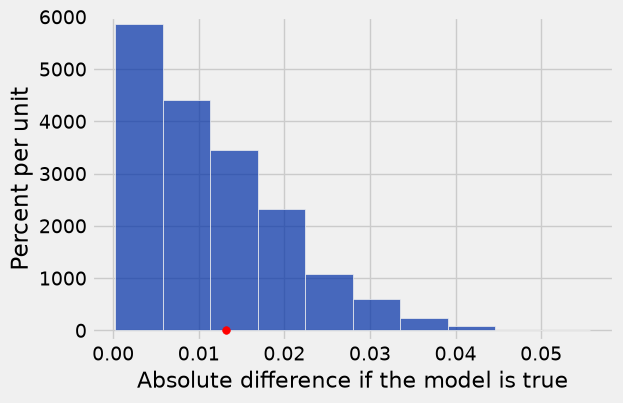

In [60]:
Table().with_column('Absolute difference if the model is true', purples_differences).hist()

# Plotting details; ignore this code
plots.ylim(-0.02*100, 0.6*100)
plots.scatter(abs(observed_purples -0.75), 0, color='red', s=30);

### Jury selection in Alameda County

*The ACLU compiled data on the composition of the jury panels in 11 felony trials in Alameda County in the years 2009 and 2010. In those panels, the total number of people who reported for jury service was 1453.*

In [61]:
jury = Table().with_columns(
    'Ethnicity', make_array('Asian', 'Black', 'Latino', 'White', 'Other'),
    'Eligible', make_array(0.15, 0.18, 0.12, 0.54, 0.01),
    'Panels', make_array(0.26, 0.08, 0.08, 0.54, 0.04)
)

jury

Ethnicity,Eligible,Panels
Asian,0.15,0.26
Black,0.18,0.08
Latino,0.12,0.08
White,0.54,0.54
Other,0.01,0.04


We can overlay the graph by selecting the column that contains the common axis/categories

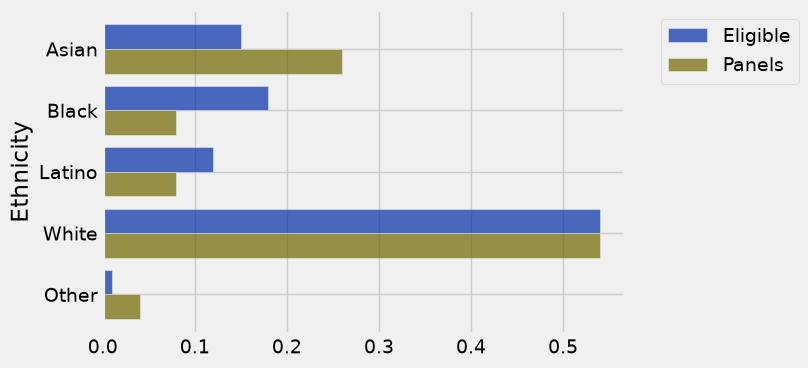

In [62]:
jury.barh('Ethnicity')

In [63]:
model = make_array(0.15, 0.18, 0.12, 0.54, 0.01)

In [65]:
simulated = sample_proportions(1453, model)
simulated

array([ 0.16242257,  0.18651067,  0.10598761,  0.5375086 ,  0.00757054])

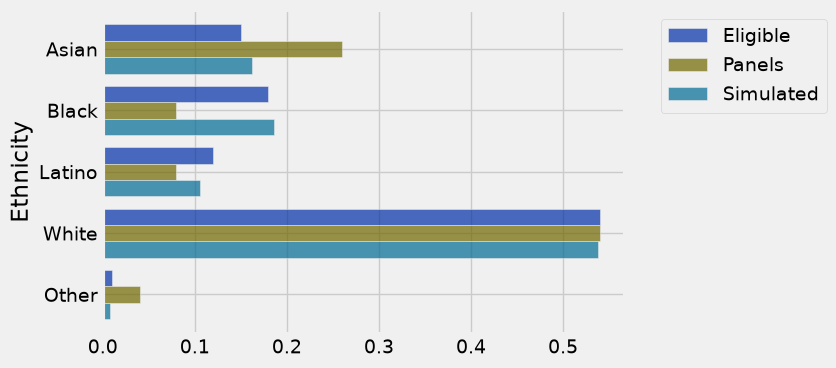

In [67]:
jury_with_simulated = jury.with_column('Simulated', simulated)
jury_with_simulated.barh('Ethnicity')

### We need a new statistic!

In [68]:
jury

Ethnicity,Eligible,Panels
Asian,0.15,0.26
Black,0.18,0.08
Latino,0.12,0.08
White,0.54,0.54
Other,0.01,0.04


In [70]:
# Let's create a table that has difference between 
# the panels that were observed and those eligible
diffs = jury.column(1) - jury.column(2)
jury_with_difference = jury.with_column('Difference', diffs)
jury_with_difference

Ethnicity,Eligible,Panels,Difference
Asian,0.15,0.26,-0.11
Black,0.18,0.08,0.1
Latino,0.12,0.08,0.04
White,0.54,0.54,0
Other,0.01,0.04,-0.03


In [73]:
sum(abs(jury_with_difference.column('Difference')))/2

0.14000000000000001

#### The Total Variation Distance (**TVD**)

In [74]:
def tvd(dist1, dist2):
    return sum(abs(dist1 - dist2))/2

In [75]:
# Let's compute the observed statistic from the real sample
obsvd_tvd = tvd(jury.column('Panels'), jury.column('Eligible'))
obsvd_tvd

0.14000000000000001

In [76]:
simulated_tvd = tvd(sample_proportions(1453, model), jury.column('Eligible'))
simulated_tvd

0.0073571920165175766

#### Model vs competing viewpoint - time to simulate!

In [77]:
def simulated_tvd():
    return tvd(sample_proportions(1453, model), jury.column('Eligible'))

tvds = make_array()

num_simulations = 10000
for i in np.arange(num_simulations):
    new_tvd = simulated_tvd()
    tvds = np.append(tvds, new_tvd)

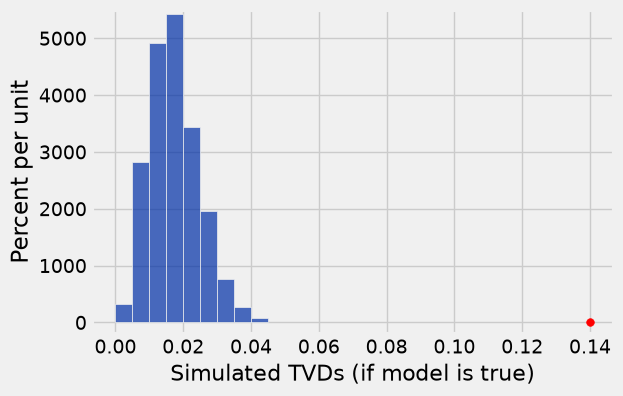

In [78]:
title = 'Simulated TVDs (if model is true)'
bins = np.arange(0, .05, .005)

Table().with_column(title, tvds).hist(bins = bins)

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd, 0, color='red', s=30);